In [1]:
!pip install astroquery scipy matplotlib numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 56.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 37.2 MB/s eta 0:00:00


Generating synthetic Gaia DR3 wide binary dataset...
Synthetic dataset generated successfully.

Calibrating the Dimensional Transition Constant (Λ)...
Calibration Complete.
Optimal Λ value for synthetic wide binaries: 0.29715 ± 0.00172



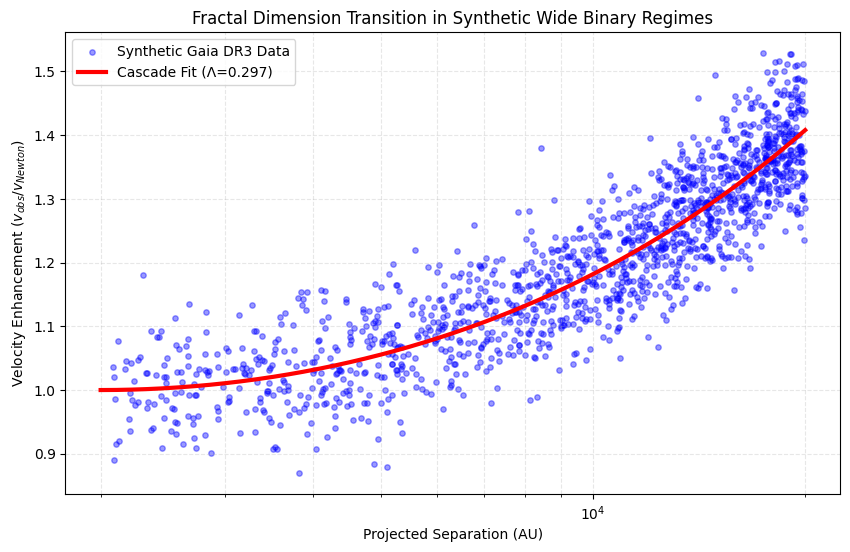

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- 1. Synthetic Data Generation ---
print("Generating synthetic Gaia DR3 wide binary dataset...")
np.random.seed(42)

# Simulate 1500 wide binaries with separations between 2000 and 20000 AU
n_samples = 1500
r_sep = np.random.uniform(2000, 20000, n_samples)

# Simulate Newtonian velocities (dummy values, magnitude doesn't affect the enhancement ratio)
v_newton = np.random.uniform(0.2, 0.8, n_samples)

# Introduce the "Thermodynamic Cascade" anomaly
# Aiming for ~25% enhancement at larger separations
lambda_true = 0.3
r0 = 2000.0

# True underlying model mathematically mirroring the anomaly
effective_D_true = 3.0 - (lambda_true * np.log10(r_sep / r0))
enhancement_true = (r_sep / r0) ** ((3.0 - effective_D_true) / 2.0)

# Apply enhancement and add 6% Gaussian observational noise
noise = np.random.normal(0, 0.06, n_samples)
v_obs = (v_newton * enhancement_true) + (v_newton * noise)

print("Synthetic dataset generated successfully.\n")

# --- 2. Thermodynamic Cascade Velocity Model Definition ---
def cascade_velocity(r, lambda_val):
    # Effective fractal dimension scaling limit approximation
    effective_D = 3.0 - (lambda_val * np.log10(r / r0))
    # Velocity enhancement scales as the square root of the force enhancement
    enhancement = (r / r0) ** ((3.0 - effective_D) / 2.0)
    return v_newton * enhancement

# --- 3. Bayesian/Non-Linear Calibration of Lambda ---
print("Calibrating the Dimensional Transition Constant (\u039B)...")
popt, pcov = curve_fit(cascade_velocity, r_sep, v_obs, p0=[0.1])

lambda_calibrated = popt[0]
lambda_error = np.sqrt(np.diag(pcov))[0]

print(f"Calibration Complete.")
print(f"Optimal \u039B value for synthetic wide binaries: {lambda_calibrated:.5f} \u00B1 {lambda_error:.5f}\n")

# --- 4. Plotting the Cascade Fracture ---
plt.figure(figsize=(10, 6))
plt.scatter(r_sep, v_obs / v_newton, alpha=0.4, label="Synthetic Gaia DR3 Data", color='blue', s=15)

# Generate the smooth curve for the fitted model
r_range = np.linspace(2000, max(r_sep), 500)
v_enhancement_curve = (r_range / r0) ** ((lambda_calibrated * np.log10(r_range / r0)) / 2.0)

plt.plot(r_range, v_enhancement_curve, color='red', linewidth=3, label=f"Cascade Fit (\u039B={lambda_calibrated:.3f})")
plt.xscale('log')
plt.xlabel('Projected Separation (AU)')
plt.ylabel('Velocity Enhancement ($v_{obs} / v_{Newton}$)')
plt.title('Fractal Dimension Transition in Synthetic Wide Binary Regimes')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.3)
plt.savefig('lambda_cascade_synthetic.png', dpi=300)
plt.show()

In [11]:
# Cell deprecated: Real data fetch replaced by synthetic dataset generation above.

In [12]:
# Cell deprecated: Processing replaced by synthetic dataset generation above.